# ENDICEX · Visualización de conglomerados K1–K5


Este notebook permite reproducir y explorar gráficamente los resultados del análisis multivariante de ENDICEX, a partir del archivo `ENDICEX_Resultados_PCA_Kmeans_K5.xlsx`, hoja `Base_111`.

La muestra comprende **111 entidades locales**, de las cuales **101 participan en la segmentación K-means (K=5)** y 10 no disponen de cuentas rendidas de 2024. Se utilizan las componentes principales y las asignaciones K1–K5 previamente calculadas, **sin reajustar los modelos PCA ni K-means**.

Se generan visualizaciones complementarias:

- **Comparación bidimensional (2D):** proyecciones PCS1–PCF1 y PCS1–PCF2, con centroides y un panel adicional sobre las entidades sin cuentas rendidas de 2024. Se exporta en PNG y SVG.
- **Representación tridimensional interactiva (Plotly):** distribución de las 101 entidades en el espacio PCA, con envolventes semitransparentes, centroides, etiquetas K1–K5 y navegación interactiva. Se exporta en HTML autónomo.

Se incluyen además dos figuras independientes, PCS1 × PCF2 y entidades sin cuentas rendidas de 2024, exportables como PNG y SVG en un ZIP.

Las envolventes convexas tienen carácter descriptivo y no representan fronteras del algoritmo K-means. Los resultados son exploratorios y no constituyen hallazgos de fiscalización.


In [41]:

### 1. Carga y validación de los resultados definitivos de ENDICEX
# Se importa el archivo ENDICEX_Resultados_PCA_Kmeans_K5.xlsx,
# utilizando la hoja Base_111, con los encabezados en la cuarta fila.
# Se comprueba la integridad de la muestra de 111 entidades:
# - 101 clasificadas en los cinco conglomerados K1–K5.
# - 10 sin cuentas rendidas de 2024: cuatro con rendición en 2023
#   y seis sin rendición en ninguno de los dos ejercicios.
# Se verifican los códigos INE, las coordenadas PCA, los tamaños
# de los conglomerados y la inclusión de Ceuta y Melilla.
# Se conservan las asignaciones originales, sin recalcular PCA ni K-means.
# Los datos validados se utilizarán en las visualizaciones posteriores.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from zipfile import ZipFile, ZIP_DEFLATED
from scipy.spatial import ConvexHull, QhullError

### 1. Archivo definitivo y parámetros comunes
# No se recalcula PCA ni K-means; se representan exclusivamente las columnas ya publicadas.
EXCEL = 'ENDICEX_Resultados_PCA_Kmeans_K5.xlsx'
PNG = 'ENDICEX_Comparacion_PCS_PCF1_PCF2.png'
SVG = 'ENDICEX_Comparacion_PCS_PCF1_PCF2.svg'
COLORES = {
    'K1': '#007CB9', 'K2': '#65AC34', 'K3': '#EDC446',
    'K4': '#FF8A16', 'K5': '#F93F45'
}
TAMANOS = {'K1':13, 'K2':48, 'K3':32, 'K4':4, 'K5':4}
X = 'PC1 social tipificado'
P1 = 'PC1 financiero ponderado'
P2 = 'PC2 financiero ponderado'
CL = 'Cluster K-means K5'


def localizar_base():
    ruta = Path(EXCEL)
    if ruta.is_file():
        return ruta
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(f'No se encuentra {EXCEL} en el directorio actual.') from exc
    print('Sube el Excel de resultados:', EXCEL)
    subidos = files.upload()
    candidatos = [Path(f) for f in subidos if f.lower().endswith('.xlsx')]
    if len(candidatos) != 1:
        raise ValueError('Debes subir exactamente un archivo .xlsx: ENDICEX_Resultados_PCA_Kmeans_K5.')
    return candidatos[0]


### 1.2. Validación y trazabilidad de las 111 entidades
def obtener_datos(ruta):
    datos = pd.read_excel(ruta, sheet_name='Base_111', header=3, dtype={'codigo_ine': str})
    requeridas = [X, P1, P2, CL, 'codigo_ine', 'cuentas 24', 'Cuentas 23']
    faltan = sorted(set(requeridas) - set(datos.columns))
    if faltan:
        raise ValueError('Columnas ausentes de Base_111: ' + ', '.join(faltan))

    datos['codigo_ine'] = datos['codigo_ine'].astype(str).str.zfill(5)
    for nombre in [X, P1, P2, 'cuentas 24', 'Cuentas 23']:
        datos[nombre] = pd.to_numeric(datos[nombre], errors='coerce')

    clasificados = datos.loc[datos[CL].isin(COLORES)].copy()
    excluidos = datos.loc[datos['cuentas 24'].eq(0) & datos[CL].isna()].copy()
    solo_2023 = excluidos.loc[excluidos['Cuentas 23'].eq(1)].copy()
    sin_ambas = excluidos.loc[excluidos['Cuentas 23'].eq(0)].copy()

    # Controles obligatorios: nunca mezclar exclusiones con clústeres.
    if len(datos) != 111 or len(clasificados) != 101 or len(excluidos) != 10:
        raise ValueError('La base debe contener exactamente 111 entidades: 101 K-means + 10 excluidas.')
    if clasificados[CL].value_counts().to_dict() != TAMANOS:
        raise ValueError('Han cambiado los tamaños K1=13, K2=48, K3=32, K4=4, K5=4.')
    if len(solo_2023) != 4 or len(sin_ambas) != 6:
        raise ValueError('Las exclusiones deben ser: 4 solo cuentas de 2023 y 6 sin 2023 ni 2024.')
    if not clasificados['cuentas 24'].eq(1).all():
        raise ValueError('Hay municipios clasificados sin las cuentas de 2024.')
    puente = datos.loc[datos['codigo_ine'].eq('14056')]
    if len(puente) != 1 or puente.iloc[0][CL] != 'K3' or puente.iloc[0]['cuentas 24'] != 1:
        raise ValueError('ENT-20AED1AC (14056) debe estar clasificado en K3: rindió 2024.')
    if not np.isfinite(clasificados[[X, P1, P2]].to_numpy(dtype=float)).all():
        raise ValueError('Coordenadas PCS, PCF1, PCF2 no finitas en los clasificados.')
    if not np.isfinite(excluidos[X].to_numpy(dtype=float)).all():
        raise ValueError('Faltan puntuaciones PCS en los excluidos.')
    print('VALIDACIÓN: 111 entidades = 101 clasificadas + 10 excluidas (4 solo 2023, 6 ninguna).')
    print('ENT-20AED1AC: incluido en K3, fuera del panel de exclusiones.')
    return datos, clasificados, solo_2023, sin_ambas



### 1.1. Carga validada del archivo de resultados
# Las cabeceras del Excel están en la fila 4; se conservan los códigos INE como texto.
ruta_excel = localizar_base()
df, clasificados, solo_2023, sin_ambas = obtener_datos(ruta_excel)
assert df['codigo_ine'].nunique() == 111, 'Los códigos INE deben ser únicos.'
assert df.shape[1] == 36, f'Se esperan 36 columnas; hay {df.shape[1]}.'
assert clasificados['codigo_ine'].isin(['51001', '52001']).sum() == 2, 'Ceuta y Melilla deben participar.'
print('Excel:', ruta_excel.name)
print('Distribución K1–K5:', clasificados[CL].value_counts().sort_index().to_dict())


VALIDACIÓN: 111 entidades = 101 clasificadas + 10 excluidas (4 solo 2023, 6 ninguna).
ENT-20AED1AC: incluido en K3, fuera del panel de exclusiones.
Excel: ENDICEX_Resultados_PCA_Kmeans_K5.xlsx
Distribución K1–K5: {'K1': 13, 'K2': 48, 'K3': 32, 'K4': 4, 'K5': 4}


Gráfico exportado: ENDICEX_Comparacion_PCS_PCF1_PCF2.png y ENDICEX_Comparacion_PCS_PCF1_PCF2.svg


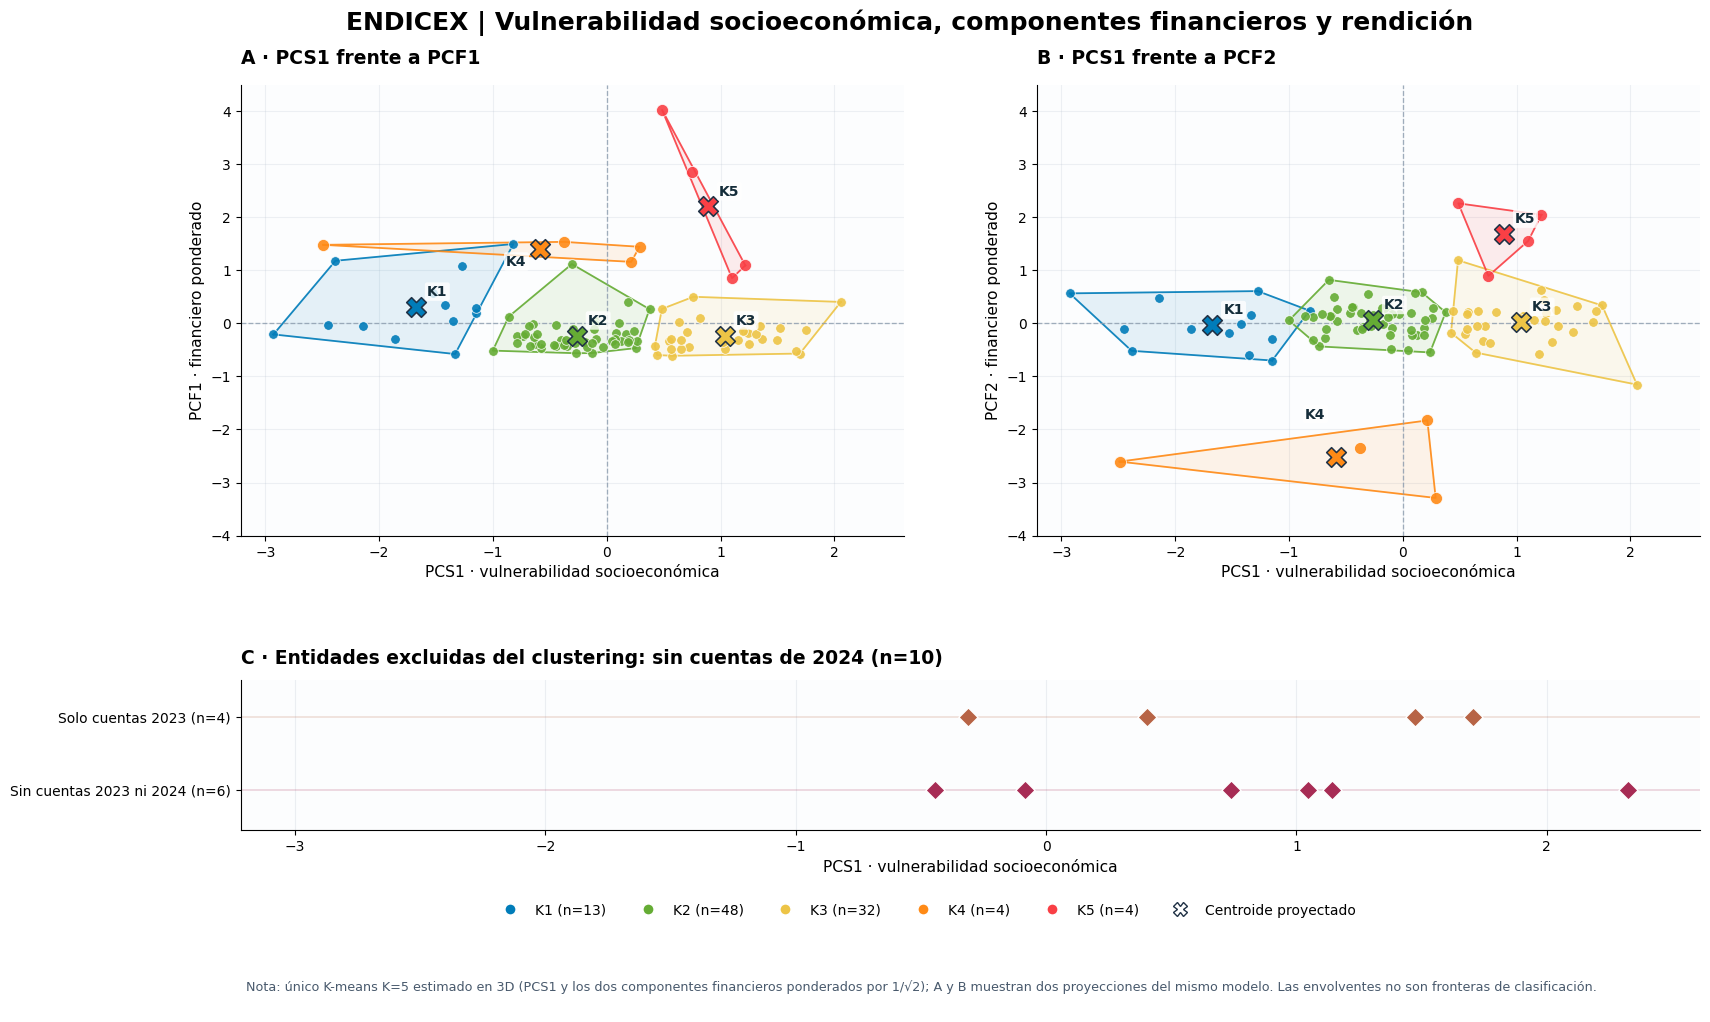

In [42]:
### 2. Comparación bidimensional de los conglomerados y situación de rendición
# Se representan dos proyecciones del mismo modelo K-means K=5:
# - Panel A: PCS1 frente a PCF1.
# - Panel B: PCS1 frente a PCF2.
# Ambos paneles utilizan las 101 entidades ya clasificadas,
# sin recalcular PCA ni K-means, y muestran centroides proyectados
# y envolventes convexas con finalidad exclusivamente descriptiva.
# El Panel C sitúa las 10 entidades sin cuentas rendidas de 2024
# sobre el eje social PCS1, diferenciando entre las que rindieron
# solo 2023 y las que no rindieron ni 2023 ni 2024.
# Se unifica la escala vertical de los paneles A y B para facilitar
# la comparación visual entre las dos dimensiones financieras.

def dibujar_comparacion_2d():
    datos = df
    plt.rcParams.update({
        'font.family': 'DejaVu Sans', 'font.size': 10,
        'svg.fonttype': 'none',  # texto editable en el SVG
    })

    fig = plt.figure(figsize=(16.4, 10.7), facecolor='white')
    rejilla = fig.add_gridspec(
        nrows=2, ncols=2, height_ratios=[3.3, 1.1],
        left=0.092, right=0.982, top=0.895, bottom=0.198,
        wspace=0.20, hspace=0.48
    )
    ax1 = fig.add_subplot(rejilla[0, 0])
    ax2 = fig.add_subplot(rejilla[0, 1], sharex=ax1)
    ax_r = fig.add_subplot(rejilla[1, :], sharex=ax1)
    fig.suptitle('ENDICEX | Vulnerabilidad socioeconómica, componentes financieros y rendición',
                 fontsize=18, fontweight='bold', y=0.965)

    for ax, eje_y, titulo, etiqueta in [
        (ax1, P1, 'A · PCS1 frente a PCF1', 'PCF1 · financiero ponderado'),
        (ax2, P2, 'B · PCS1 frente a PCF2', 'PCF2 · financiero ponderado'),
    ]:
        for k, color in COLORES.items():
            pts = clasificados.loc[clasificados[CL].eq(k), [X, eje_y]].to_numpy(dtype=float)
            if len(pts) >= 3:
                try:
                    hull = ConvexHull(pts)
                    vertices = pts[hull.vertices]
                    ax.fill(vertices[:,0], vertices[:,1], color=color,
                            alpha=0.095, zorder=1)
                    borde = np.vstack([vertices, vertices[0]])
                    ax.plot(borde[:,0], borde[:,1], color=color,
                            lw=1.3, alpha=0.9, zorder=2)
                except QhullError:
                    pass
            ax.scatter(pts[:,0], pts[:,1], s=48 if len(pts)>5 else 75,
                       c=color, alpha=0.9, linewidths=0.55,
                       edgecolors='white', zorder=4)
            # Media proyectada de los miembros del mismo clúster 3D,
            # sin recalcular el modelo ni sustituirlo por un K-means 2D.
            cx, cy = pts.mean(axis=0)
            ax.scatter(cx, cy, marker='X', s=200, c=color,
                       edgecolors='#203246', linewidths=1.15, zorder=6)
            # Ajuste de etiquetas K4:
            # SOLO se desplaza un poco más en el Panel B (eje_y == P2) para no cortar el perímetro.
            if k == 'K4':
                if eje_y == P2:
                    desplazamiento = (-22, 28)  # Desplazado más arriba/izquierda en el Panel B
                else:
                    desplazamiento = (-24, -12) # Se conserva idéntico en el Panel A
            else:
                desplazamiento = (8, 8)

            ax.annotate(k, (cx, cy), xytext=desplazamiento, textcoords='offset points',
                        fontsize=10, color='#152D3A', fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.16', facecolor='white',
                                  alpha=0.80, edgecolor='none'), zorder=7)

        ax.axhline(0, color='#8B9BAD', ls='--', lw=0.95, alpha=.8)
        ax.axvline(0, color='#8B9BAD', ls='--', lw=0.95, alpha=.8)
        ax.set_facecolor('#FCFDFE')
        ax.grid(color='#A1AEC0', alpha=.17)
        ax.set_axisbelow(True)
        ax.set_title(titulo, fontsize=13.5, weight='bold', loc='left', pad=15)
        ax.set_xlabel('PCS1 · vulnerabilidad socioeconómica', fontsize=11.2)
        ax.set_ylabel(etiqueta, fontsize=11.2)
        ax.spines[['top', 'right']].set_visible(False)

    # MODIFICACIÓN SOLICITADA: misma escala vertical en los paneles A y B.
    # De este modo, el valor 0 queda EXACTAMENTE a la misma altura y la
    # longitud gráfica de una unidad financiera también es idéntica.
    # Los extremos incluyen TODOS los puntos, sin alterar ninguna coordenada.
    Y_MIN, Y_MAX = -4.0, 4.5
    if (clasificados[[P1, P2]].min().min() < Y_MIN or
            clasificados[[P1, P2]].max().max() > Y_MAX):
        raise ValueError('Los límites verticales no abarcan las puntuaciones financieras.')
    ax1.set_ylim(Y_MIN, Y_MAX)
    ax2.set_ylim(Y_MIN, Y_MAX)
    ax1.set_yticks(np.arange(-4, 5, 1))
    ax2.set_yticks(np.arange(-4, 5, 1))

    # Idéntico eje social para los 3 paneles, incluidas las 10 exclusiones.
    xs = datos[X].to_numpy(dtype=float)
    margen = max(0.25, np.ptp(xs) * .055)
    ax1.set_xlim(np.nanmin(xs)-margen, np.nanmax(xs)+margen)

    ax_r.scatter(solo_2023[X], np.ones(len(solo_2023)), marker='D', s=95,
                 c='#B76446', edgecolors='white', linewidths=1.0, zorder=4,
                 label='Solo cuenta 2023 · n=4')
    ax_r.scatter(sin_ambas[X], np.zeros(len(sin_ambas)), marker='D', s=95,
                 c='#A72C55', edgecolors='white', linewidths=1.0, zorder=4,
                 label='Sin cuentas 2023 ni 2024 · n=6')
    ax_r.axhline(1, color='#B76446', linewidth=1.1, alpha=.22)
    ax_r.axhline(0, color='#A72C55', linewidth=1.1, alpha=.22)
    ax_r.set_yticks([0,1])
    ax_r.set_yticklabels(['Sin cuentas 2023 ni 2024 (n=6)',
                          'Solo cuentas 2023 (n=4)'], fontsize=10.0)
    ax_r.set_ylim(-0.55, 1.5)
    ax_r.set_title('C · Entidades excluidas del clustering: sin cuentas de 2024 (n=10)',
                   fontsize=13.5, fontweight='bold', loc='left', pad=12)
    ax_r.set_xlabel('PCS1 · vulnerabilidad socioeconómica', fontsize=11.2)
    ax_r.grid(axis='x', color='#A1AEC0', alpha=.18)
    ax_r.set_axisbelow(True)
    ax_r.set_facecolor('#FCFDFE')
    ax_r.spines[['top','right']].set_visible(False)

    leyenda = [Line2D([], [], marker='o', linestyle='', markersize=8,
                       markerfacecolor=color, markeredgecolor='white',
                       label=f'{k} (n={TAMANOS[k]})') for k, color in COLORES.items()]
    leyenda.append(Line2D([], [], marker='X', linestyle='', markersize=10,
                          markerfacecolor='white', markeredgecolor='#203246',
                          label='Centroide proyectado'))
    fig.legend(handles=leyenda, loc='lower center', ncol=6,
               bbox_to_anchor=(.51, .105), fontsize=10, frameon=False)
    fig.text(0.095, .043,
             'Nota: único K-means K=5 estimado en 3D (PCS1 y los dos componentes financieros ponderados por 1/√2); '
             'A y B muestran dos proyecciones del mismo modelo. Las envolventes no son fronteras de clasificación.\n',
             fontsize=9.2, color='#48596C', ha='left', va='center', linespacing=1.5)

    fig.savefig(PNG, dpi=260, facecolor='white', bbox_inches='tight')
    fig.savefig(SVG, facecolor='white', bbox_inches='tight')
    print('Gráfico exportado:', PNG, 'y', SVG)
    plt.show()



dibujar_comparacion_2d()

### Figuras independientes para su revisión

El gráfico conjunto anterior **ya presenta PCS1 × PCF2 en su panel B**, y las **10 entidades sin cuentas rendidas de 2024 en su panel C**. Para facilitar la revisión de estos dos resultados, se reproducen a continuación como figuras independientes, sin cambiar los PCA ni el modelo K-means.

- **PCS1 × PCF2:** las 101 entidades clasificadas, los cinco grupos, sus centroides proyectados y envolventes descriptivas.
- **Sin rendición 2024:** las 10 entidades excluidas del clustering, situadas únicamente según su PCS1 social y diferenciadas por rendición en 2023 (cuatro frente a seis). No se representan coordenadas PCF1/PCF2 para estas entidades, ya que no forman parte de la segmentación.
- Las figuras **no muestran nombres ni códigos INE** y se exportan en PNG y SVG. La celda de descarga opcional genera un único ZIP con los cuatro archivos.

**Precaución:** son visualizaciones descriptivas de una muestra exploratoria no representativa. La pertenencia a un conglomerado no constituye un hallazgo de fiscalización.


In [ ]:
### 2.1. Figura independiente: PCS1 frente a PCF2 (101 entidades K1–K5)
# Reutiliza exclusivamente los PCA y clústeres definitivos cargados en la celda 1.
# La proyección 2D NO supone volver a ajustar K-means sobre dos dimensiones.
# Sin códigos INE ni nombres de municipios en el gráfico.

SALIDA_PCS_PCF2_PNG = 'ENDICEX_PCS1_vs_PCF2_K5.png'
SALIDA_PCS_PCF2_SVG = 'ENDICEX_PCS1_vs_PCF2_K5.svg'

fig_pcf2, ax_pcf2 = plt.subplots(figsize=(11.8, 7.2), facecolor='white')
for grupo, color in COLORES.items():
    sub = clasificados.loc[clasificados[CL].eq(grupo)]
    valores = sub[[X, P2]].to_numpy(dtype=float)
    if len(valores) >= 3:
        try:
            hull = ConvexHull(valores)
            vertices = valores[hull.vertices]
            ax_pcf2.fill(vertices[:, 0], vertices[:, 1],
                         facecolor=color, edgecolor='none', alpha=.10, zorder=1)
            contorno = np.vstack([vertices, vertices[0]])
            ax_pcf2.plot(contorno[:, 0], contorno[:, 1],
                         color=color, lw=1.3, alpha=.88, zorder=2)
        except QhullError:
            pass

    ax_pcf2.scatter(valores[:, 0], valores[:, 1],
                     s=56 if len(valores) > 5 else 80,
                     color=color, alpha=.88, edgecolors='white',
                     linewidths=.75, zorder=4, label=f'{grupo} (n={len(valores)})')
    centroide = valores.mean(axis=0)
    ax_pcf2.scatter(*centroide, color=color, marker='X', s=215,
                     edgecolors='#233c4a', linewidths=1, zorder=6)
    desplazamiento = (-23, 23) if grupo == 'K4' else (9, 9)
    ax_pcf2.annotate(grupo, centroide, xytext=desplazamiento,
                     textcoords='offset points', fontsize=11,
                     color='#173444', fontweight='bold',
                     bbox=dict(boxstyle='round,pad=.2', facecolor='white',
                               edgecolor='none', alpha=.84), zorder=7)

ax_pcf2.axhline(0, color='#8B9BAD', ls='--', lw=.95, alpha=.75)
ax_pcf2.axvline(0, color='#8B9BAD', ls='--', lw=.95, alpha=.75)
ax_pcf2.grid(color='#A1AEC0', alpha=.19)
ax_pcf2.set_axisbelow(True)
ax_pcf2.set_facecolor('#FCFDFE')
ax_pcf2.set_xlabel('PCS1 · componente social tipificada', fontsize=12)
ax_pcf2.set_ylabel('PCF2 · segunda componente financiera ponderada', fontsize=12)
ax_pcf2.set_title('ENDICEX | PCS1 frente a PCF2', fontsize=19, fontweight='bold', loc='left', pad=20)
ax_pcf2.text(0, 1.01, '101 entidades clasificadas · K-means K=5 en tres dimensiones',
             transform=ax_pcf2.transAxes, fontsize=10.5, color='#64798A')
ax_pcf2.spines[['top', 'right']].set_visible(False)
ax_pcf2.legend(loc='best', ncol=2, fontsize=10, frameon=True,
               facecolor='white', edgecolor='#D5E0E5')
fig_pcf2.text(.08, .018, 'Cruces: centroides proyectados. Contornos: envolventes convexas descriptivas, no fronteras de clasificación.',
              fontsize=9, color='#556979', ha='left')
fig_pcf2.tight_layout(rect=[0.025, .042, .98, .97])

fig_pcf2.savefig(SALIDA_PCS_PCF2_PNG, dpi=260, facecolor='white', bbox_inches='tight')
fig_pcf2.savefig(SALIDA_PCS_PCF2_SVG, facecolor='white', bbox_inches='tight')
plt.show()
print('Archivos generados:', SALIDA_PCS_PCF2_PNG, '|', SALIDA_PCS_PCF2_SVG)


In [ ]:
### 2.2. Figura independiente: las 10 entidades sin cuentas rendidas de 2024
# Son observaciones EXCLUIDAS de K-means, no un sexto conglomerado.
# El eje X representa el PCS1 real; no se estiman componentes financieras
# inexistentes para las entidades sin cuentas. No se muestran identificadores.

SALIDA_NO_RENDICION_PNG = 'ENDICEX_Sin_Rendicion_2024_PCS1.png'
SALIDA_NO_RENDICION_SVG = 'ENDICEX_Sin_Rendicion_2024_PCS1.svg'

fig_excl, ax_excl = plt.subplots(figsize=(11.7, 5.0), facecolor='white')
grupos_excluidos = [
    (solo_2023, 1, '#B76446', 'Rindieron 2023; no 2024 (n=4)'),
    (sin_ambas, 0, '#A72C55', 'No rindieron ni 2023 ni 2024 (n=6)'),
]
# Desplazamiento mínimo, reproducible y únicamente visual si hay puntos superpuestos.
generador_excl = np.random.default_rng(2024)
for datos_excluidos, posicion, color, etiqueta in grupos_excluidos:
    coordenadas = datos_excluidos[X].to_numpy(dtype=float)
    if len(coordenadas) == 0 or not np.isfinite(coordenadas).all():
        raise ValueError('Faltan puntuaciones sociales PCS1 de entidades sin rendición.')
    dispersion = generador_excl.uniform(-.055, .055, size=len(coordenadas))
    ax_excl.axhline(posicion, color=color, lw=1.1, alpha=.18, zorder=1)
    ax_excl.scatter(coordenadas, np.full(len(coordenadas), posicion) + dispersion,
                    marker='D', s=125, color=color,
                    edgecolors='white', linewidths=1.05, zorder=4,
                    label=etiqueta)

ax_excl.axvline(0, color='#8598A9', ls='--', lw=1)
xs_total = df[X].to_numpy(dtype=float)
margen_excl = max(.25, np.ptp(xs_total) * .055)
ax_excl.set_xlim(float(np.min(xs_total) - margen_excl),
                 float(np.max(xs_total) + margen_excl))
ax_excl.set_ylim(-.34, 1.45)
ax_excl.set_yticks([0, 1], [
    'Sin rendición en 2023 y 2024 · 6',
    'Rendición solo en 2023 · 4'
])
ax_excl.set_xlabel('PCS1 · componente social tipificada', fontsize=12)
ax_excl.set_title('ENDICEX | Entidades sin cuentas rendidas de 2024',
                  fontsize=18, fontweight='bold', loc='left', pad=20)
ax_excl.text(0, 1.02, '10 de las 111 entidades de partida · excluidas de la segmentación K-means',
             transform=ax_excl.transAxes, fontsize=10.5, color='#61778B')
ax_excl.set_facecolor('#FCFDFE')
ax_excl.grid(axis='x', color='#A1AEC0', alpha=.18)
ax_excl.set_axisbelow(True)
ax_excl.spines[['top', 'right']].set_visible(False)
ax_excl.legend(loc='upper right', fontsize=10, frameon=False)
fig_excl.text(.11, .025,
              'La posición horizontal es el PCS1 observado. Desplazamiento vertical mínimo solo para facilitar la lectura. '
              'Sin PCF1/PCF2 ni asignación a conglomerados.',
              fontsize=9.0, color='#586D7D', ha='left')
fig_excl.tight_layout(rect=[0.02, .055, .98, .96])

fig_excl.savefig(SALIDA_NO_RENDICION_PNG, dpi=260, facecolor='white', bbox_inches='tight')
fig_excl.savefig(SALIDA_NO_RENDICION_SVG, facecolor='white', bbox_inches='tight')
plt.show()
print('Archivos generados:', SALIDA_NO_RENDICION_PNG, '|', SALIDA_NO_RENDICION_SVG)


In [ ]:
### 2.3. Descargar juntas las dos figuras independientes (PNG + SVG)
# En Colab se descarga un único ZIP. Fuera de Colab se muestra la ruta.
# Ejecuta previamente 2.1 y 2.2; las figuras se crean sin recalcular PCA ni K-means.

ARCHIVOS_INDEPENDIENTES = [
    SALIDA_PCS_PCF2_PNG, SALIDA_PCS_PCF2_SVG,
    SALIDA_NO_RENDICION_PNG, SALIDA_NO_RENDICION_SVG
]
faltantes_independientes = [ruta for ruta in ARCHIVOS_INDEPENDIENTES if not Path(ruta).is_file()]
if faltantes_independientes:
    raise FileNotFoundError('Ejecuta antes las celdas 2.1 y 2.2; faltan: ' +
                            ', '.join(faltantes_independientes))

ZIP_INDEPENDIENTES = 'ENDICEX_PCS1_PCF2_y_Sin_Rendicion_2024.zip'
with ZipFile(ZIP_INDEPENDIENTES, 'w', compression=ZIP_DEFLATED) as paquete:
    for ruta in ARCHIVOS_INDEPENDIENTES:
        paquete.write(ruta, arcname=Path(ruta).name)
print('Figuras para revisión:', Path(ZIP_INDEPENDIENTES).resolve())
try:
    from google.colab import files as colab_files
except ImportError:
    pass
else:
    colab_files.download(ZIP_INDEPENDIENTES)


In [43]:
### 3. Representación tridimensional interactiva de los conglomerados K1–K5
# Se representan las 101 entidades clasificadas en el espacio PCA tridimensional:
# - Eje X: PCS1, vulnerabilidad socioeconómica.
# - Eje Y: PCF2, segunda componente financiera ponderada.
# - Eje Z: PCF1, primera componente financiera ponderada.
# Se mantienen las asignaciones y los colores definitivos K1–K5.
# Cada conglomerado incluye sus observaciones individuales, su centroide
# identificado mediante una cruz y su envolvente convexa semitransparente.
# La visualización Plotly permite rotar, ampliar y consultar los datos
# de cada entidad, así como seleccionar diferentes perspectivas.
# Se exporta un archivo HTML interactivo y autónomo.
# No se recalculan PCA ni K-means. Las envolventes son descriptivas
# y no representan fronteras estadísticas de clasificación.


import numpy as np
import plotly.graph_objects as go
from scipy.spatial import ConvexHull, QhullError

GRAFICO_HTML = "ENDICEX_Figura5_Interactiva_K5.html"
fig_interactiva = go.Figure()

for grupo, color in COLORES.items():

    sub = clasificados.loc[clasificados[CL].eq(grupo)].copy()
    puntos = sub[[X, P2, P1]].to_numpy(dtype=float)

    # Envolvente convexa tridimensional
    if len(puntos) >= 4:
        try:
            casco = ConvexHull(puntos)
            triangulos = casco.simplices

            fig_interactiva.add_trace(go.Mesh3d(
                x=puntos[:, 0],
                y=puntos[:, 1],
                z=puntos[:, 2],
                i=triangulos[:, 0],
                j=triangulos[:, 1],
                k=triangulos[:, 2],
                color=color,
                opacity=0.12,
                flatshading=True,
                hoverinfo="skip",
                showlegend=False,
                legendgroup=grupo,
                lighting=dict(
                    ambient=1,
                    diffuse=0,
                    specular=0
                )
            ))

        except QhullError:
            print(f"Sin envolvente para {grupo}")

    # Información al situar el cursor sobre una entidad
    informacion = np.column_stack([
        sub["codigo_ine"].astype(str).tolist(),
        sub["id_aleatorio"].fillna("").astype(str).tolist(),
        sub["provincia"].fillna("").astype(str).tolist()
    ])

    # Observaciones individuales: tamaño y contorno homogéneos
    fig_interactiva.add_trace(go.Scatter3d(
        x=puntos[:, 0],
        y=puntos[:, 1],
        z=puntos[:, 2],
        mode="markers",
        name=f"{grupo} (n={TAMANOS[grupo]})",
        legendgroup=grupo,
        marker=dict(
            size=3.5,
            color=color,
            opacity=0.97,
            line=dict(
                color="white",
                width=0.5
            )
        ),
        customdata=informacion,
        hovertemplate=(
            "<b>%{customdata[1]}</b><br>"
            "Código INE: %{customdata[0]}<br>"
            "Provincia: %{customdata[2]}<br>"
            "PCS1: %{x:.3f}<br>"
            "PCF2: %{y:.3f}<br>"
            "PCF1: %{z:.3f}"
            "<extra>" + grupo + "</extra>"
        )
    ))

    # Centroide del conglomerado
    centro = puntos.mean(axis=0)

    # Una única cruz X de color con contorno negro
    fig_interactiva.add_trace(go.Scatter3d(
        x=[centro[0]],
        y=[centro[1]],
        z=[centro[2]],
        mode="markers",
        legendgroup=grupo,
        showlegend=False,
        marker=dict(
            symbol="x",
            size=3,
            color=color,
            line=dict(
                color="#000000",
                width=1.5
            )
        ),
        hovertemplate=(
            f"<b>Centroide {grupo}</b><br>"
            "PCS1: %{x:.3f}<br>"
            "PCF2: %{y:.3f}<br>"
            "PCF1: %{z:.3f}<extra></extra>"
        )
    ))

    # Etiqueta K1–K5, separada ligeramente del centroide
    fig_interactiva.add_trace(go.Scatter3d(
        x=[centro[0]],
        y=[centro[1]],
        z=[centro[2] + 0.18],
        mode="text",
        text=[grupo],
        textposition="top center",
        legendgroup=grupo,
        showlegend=False,
        hoverinfo="skip",
        textfont=dict(
            size=13,
            color="#111111",
            family="Arial Black"
        )
    ))

# Perspectivas interactivas
camara_inicial = dict(
    eye=dict(x=1.55, y=1.80, z=0.92)
)

camara_opuesta = dict(
    eye=dict(x=-1.50, y=-1.65, z=0.90)
)

camara_superior = dict(
    eye=dict(x=0, y=0.02, z=2.8),
    up=dict(x=0, y=1, z=0)
)

fig_interactiva.update_layout(
    title=dict(
        text=(
            "<b>ENDICEX | Conglomerados K1–K5</b>"
            "<br><sup>101 entidades · centroides y "
            "envolventes semitransparentes</sup>"
        ),
        x=0.5,
        xanchor="center"
    ),
    template="plotly_white",
    height=790,
    margin=dict(l=10, r=10, t=112, b=90),

    legend=dict(
        title="Conglomerados",
        x=0.01,
        y=0.95,
        groupclick="togglegroup"
    ),

    scene=dict(
        xaxis=dict(
            title="PCS1 · vulnerabilidad socioeconómica",
            range=[-3.25, 2.55]
        ),
        yaxis=dict(
            title="PCF2 · financiero ponderado",
            range=[-3.70, 2.70]
        ),
        zaxis=dict(
            title="PCF1 · financiero ponderado",
            range=[-0.90, 4.35]
        ),
        camera=camara_inicial,
        aspectmode="manual",
        aspectratio=dict(
            x=5.80 / 6.40,
            y=1.0,
            z=5.25 / 6.40
        )
    ),

    updatemenus=[dict(
        type="buttons",
        direction="right",
        x=0.50,
        y=1.02,
        xanchor="center",
        yanchor="bottom",
        showactive=False,
        buttons=[
            dict(
                label="Vista inicial",
                method="relayout",
                args=[{"scene.camera": camara_inicial}]
            ),
            dict(
                label="Vista opuesta",
                method="relayout",
                args=[{"scene.camera": camara_opuesta}]
            ),
            dict(
                label="Vista superior",
                method="relayout",
                args=[{"scene.camera": camara_superior}]
            )
        ]
    )]
)

# Exportación HTML autónoma
fig_interactiva.write_html(
    GRAFICO_HTML,
    include_plotlyjs=True,
    full_html=True
)

fig_interactiva.show()

print("Gráfico interactivo generado:", GRAFICO_HTML)


Gráfico interactivo generado: ENDICEX_Figura5_Interactiva_K5.html


In [44]:
### 4.1. Validación y parámetros de la radiografía
# Se reutilizan los resultados de las celdas 1–3, sin reajustar modelos.
# Se verifica la población de 101 entidades y la correspondencia K1–K5.

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

NECESARIAS_4 = ('clasificados', 'COLORES', 'TAMANOS', 'X', 'P1', 'P2', 'CL')
faltantes_4 = [v for v in NECESARIAS_4 if v not in globals()]
if faltantes_4:
    raise RuntimeError('Ejecuta primero las celdas 1–3. Faltan: ' + ', '.join(faltantes_4))

ORDEN4 = ('K1', 'K2', 'K3', 'K4', 'K5')
COMPONENTES4 = [
    (X,  'PCS1 · Vulnerabilidad socioeconómica'),
    (P1, 'PCF1 · Primera componente financiera'),
    (P2, 'PCF2 · Segunda componente financiera'),
]
datos4 = clasificados.copy()
columnas4 = [X, P1, P2, CL, 'codigo_ine', 'id_aleatorio', 'provincia']
faltan_columnas4 = [c for c in columnas4 if c not in datos4.columns]
if faltan_columnas4:
    raise ValueError('Faltan columnas: ' + ', '.join(faltan_columnas4))

for columna, _ in COMPONENTES4:
    datos4[columna] = pd.to_numeric(datos4[columna], errors='coerce')

if len(datos4) != 101 or not np.isfinite(datos4[[X, P1, P2]].to_numpy(dtype=float)).all():
    raise ValueError('Se necesitan 101 entidades con las tres coordenadas PCA válidas.')
if datos4[CL].value_counts().to_dict() != TAMANOS:
    raise ValueError('Los tamaños de K1–K5 no coinciden con los resultados definitivos.')
if not set(ORDEN4) == set(COLORES) == set(TAMANOS):
    raise ValueError('La paleta o los tamaños de los cinco conglomerados están incompletos.')

# Una misma escala vertical en los tres paneles, sin normalización adicional.
valores4 = datos4[[X, P1, P2]].to_numpy(dtype=float)
YMIN4 = float(valores4.min() - 0.35)
YMAX4 = float(valores4.max() + 0.35)

# Semilla fija: el desplazamiento horizontal es solo una ayuda visual.
generador4 = np.random.default_rng(42)
print('Validación:', len(datos4), 'entidades; K1–K5 =', datos4[CL].value_counts().sort_index().to_dict())


Validación: 101 entidades; K1–K5 = {'K1': 13, 'K2': 48, 'K3': 32, 'K4': 4, 'K5': 4}


In [45]:
### 4.2. Distribución individual, centroides y rangos por componente
# Tres paneles: PCS1, PCF1 y PCF2; grupos K1–K5 en cada panel.
# Los intervalos verticales muestran mínimos y máximos, NO intervalos de confianza.

fig_radiografia = make_subplots(
    rows=1, cols=3, shared_yaxes=True, horizontal_spacing=0.055,
    subplot_titles=(
        'A · PCS1 · Vulnerabilidad socioeconómica',
        'B · PCF1 · Primera componente financiera',
        'C · PCF2 · Segunda componente financiera',
    ),
)

for panel, (variable, descripcion) in enumerate(COMPONENTES4, start=1):
    for posicion, grupo in enumerate(ORDEN4, start=1):
        sub = datos4.loc[datos4[CL].eq(grupo)].copy()
        color = COLORES[grupo]
        valores = sub[variable].to_numpy(dtype=float)

        # Rango de los valores individuales del conglomerado.
        fig_radiografia.add_trace(go.Scatter(
            x=[posicion, posicion], y=[float(valores.min()), float(valores.max())],
            mode='lines', line=dict(color=color, width=4), opacity=0.27,
            hoverinfo='skip', legendgroup=grupo, showlegend=False,
        ), row=1, col=panel)

        # Puntos: desplazamiento horizontal determinista para reducir superposiciones.
        horizontal = posicion + generador4.uniform(-0.18, 0.18, len(sub))
        informacion = np.column_stack([
            sub['codigo_ine'].astype(str).str.zfill(5),
            sub['id_aleatorio'].fillna('').astype(str),
            sub['provincia'].fillna('').astype(str),
        ])
        fig_radiografia.add_trace(go.Scatter(
            x=horizontal, y=valores, mode='markers',
            name=f'{grupo} (n={TAMANOS[grupo]})',
            legendgroup=grupo, showlegend=(panel == 1),
            marker=dict(color=color, size=7, opacity=0.83,
                        line=dict(color='white', width=0.6)),
            customdata=informacion,
            hovertemplate=(
                f'<b>{grupo} · {descripcion}</b><br>'
                'Identificador: %{customdata[1]}<br>'
                'Código INE: %{customdata[0]}<br>'
                'Provincia: %{customdata[2]}<br>'
                'Puntuación: <b>%{y:.4f}</b><extra></extra>'
            ),
        ), row=1, col=panel)

    # Dibujar las cruces después de los puntos para mantenerlas visibles.
    for posicion, grupo in enumerate(ORDEN4, start=1):
        media = float(datos4.loc[datos4[CL].eq(grupo), variable].mean())
        fig_radiografia.add_trace(go.Scatter(
            x=[posicion], y=[media], mode='markers',
            name='Centroide', legendgroup='centroides',
            showlegend=(panel == 1 and grupo == 'K1'),
            marker=dict(symbol='x', size=12, color=COLORES[grupo],
                        line=dict(color='#182936', width=1.5)),
            hovertemplate=(
                f'<b>Centroide {grupo}</b><br>{descripcion}<br>'
                'Media: <b>%{y:.4f}</b><extra></extra>'
            ),
        ), row=1, col=panel)


In [46]:
### 4.3. Diseño, escalas y leyenda de la radiografía
# Escala vertical común; los cinco conglomerados figuran en cada eje horizontal.
# Se explica el desplazamiento horizontal y la interpretación de los rangos.

for panel in (1, 2, 3):
    fig_radiografia.update_xaxes(
        tickmode='array', tickvals=[1, 2, 3, 4, 5], ticktext=list(ORDEN4),
        range=[0.55, 5.45], title_text='Conglomerados',
        showgrid=False, zeroline=False, row=1, col=panel,
    )
    fig_radiografia.update_yaxes(
        range=[YMIN4, YMAX4], showgrid=True,
        gridcolor='#E6EDF3', zeroline=False, row=1, col=panel,
    )
    fig_radiografia.add_hline(
        y=0, row=1, col=panel, line_color='#8A9AAB',
        line_width=1, line_dash='dash', opacity=0.7,
    )

fig_radiografia.update_yaxes(title_text='Puntuación de la componente', row=1, col=1)
fig_radiografia.update_layout(
    title=dict(
        text=('<b>ENDICEX | Radiografía de los conglomerados K1–K5</b>'
              '<br><sup>101 entidades · Valores individuales, centroides y rangos</sup>'),
        x=0.5, xanchor='center',
    ),
    template='plotly_white',
    font=dict(family='Arial', size=12, color='#263747'),
    width=1500, height=740,
    margin=dict(l=90, r=40, t=130, b=160),
    legend=dict(orientation='h', x=0.5, xanchor='center',
                y=-0.16, yanchor='top', font=dict(size=12)),
    hovermode='closest',
)

# Se añade la nota SIN reemplazar los títulos originales de los tres paneles.
fig_radiografia.add_annotation(
    text=('Cruces: medias de los conglomerados. Segmentos: rangos mínimo–máximo. '
          'El desplazamiento horizontal de las observaciones es únicamente visual.'),
    x=0.5, y=-0.29, xref='paper', yref='paper',
    showarrow=False, font=dict(size=11, color='#657588'),
    xanchor='center', align='center',
)


In [47]:
### 4.4. Visualización y exportación a HTML autónomo
# El archivo contiene Plotly integrado y puede abrirse sin conexión.
# No se generan índices ni se modifica el Excel original.

SALIDA_HTML_4 = 'ENDICEX_Radiografia_Clusters_K1_K5.html'
fig_radiografia.write_html(SALIDA_HTML_4, include_plotlyjs=True, full_html=True)
fig_radiografia.show()
print('HTML interactivo generado:', SALIDA_HTML_4)
print('Entidades representadas:', len(datos4))


HTML interactivo generado: ENDICEX_Radiografia_Clusters_K1_K5.html
Entidades representadas: 101


In [49]:
### 4.5. Descarga del gráfico
# Descarga el HTML generado sin cambiar el contenido de las figuras.

from pathlib import Path
archivo4 = Path(SALIDA_HTML_4)
if not archivo4.is_file():
    raise FileNotFoundError(f'No se ha generado {archivo4}. Ejecuta antes 4.4.')

try:
    from google.colab import files
except ImportError:
    print('Archivo guardado en:', archivo4.resolve())
else:
    files.download(str(archivo4))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>